In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "student_dataset_10000_rows.csv"
)

In [3]:
print(df["exam_score"].describe())

count    10000.000000
mean        86.704207
std         15.058383
min         26.670000
25%         76.727500
50%         92.120000
75%        100.000000
max        100.000000
Name: exam_score, dtype: float64


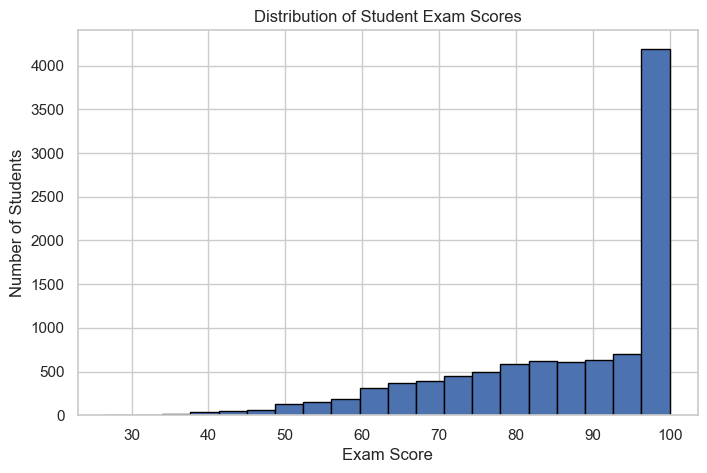

In [4]:
plt.figure(figsize=(8,5))

plt.hist(df["exam_score"],
    bins=20,
    edgecolor="black")

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.show()

In [5]:
numerical_columns = [
    "study_hours",
    "attendance",
    "sleep_hours",
    "internet_usage",
    "assignments_completed",
    "previous_score",
    "exam_score"
]

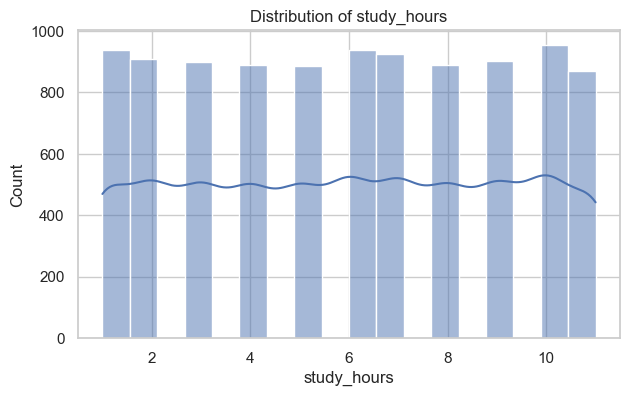

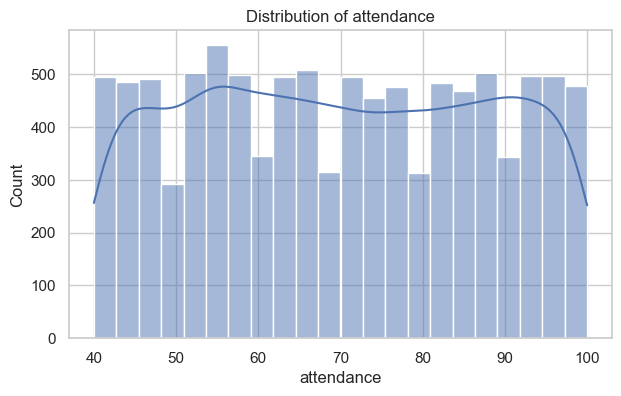

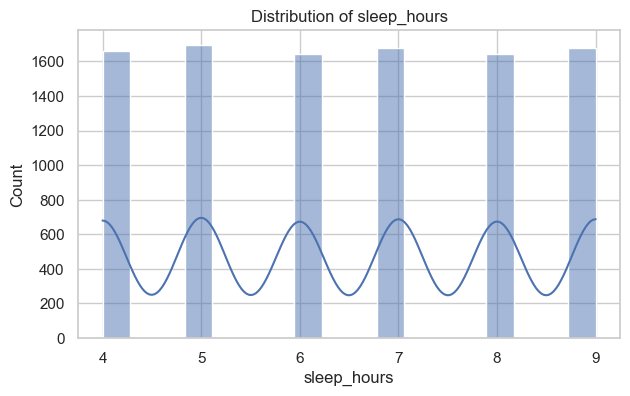

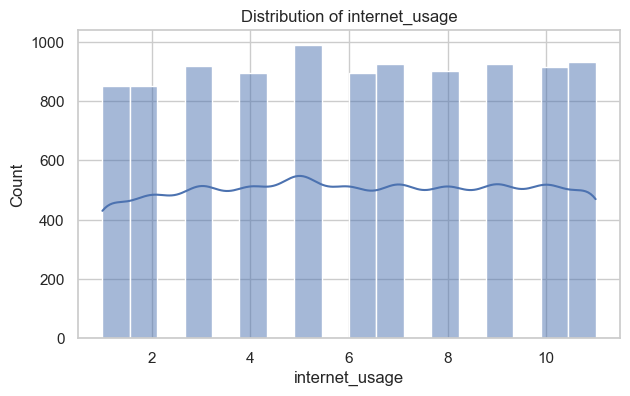

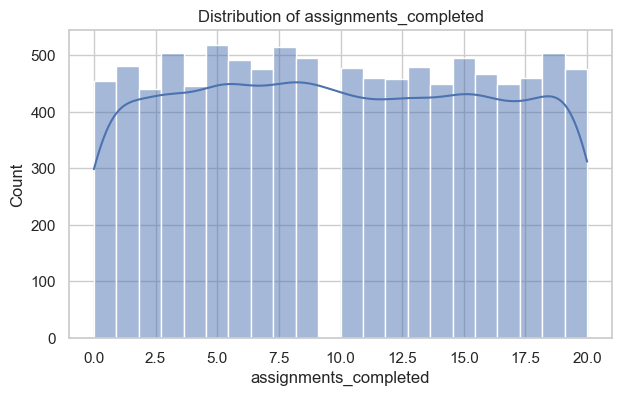

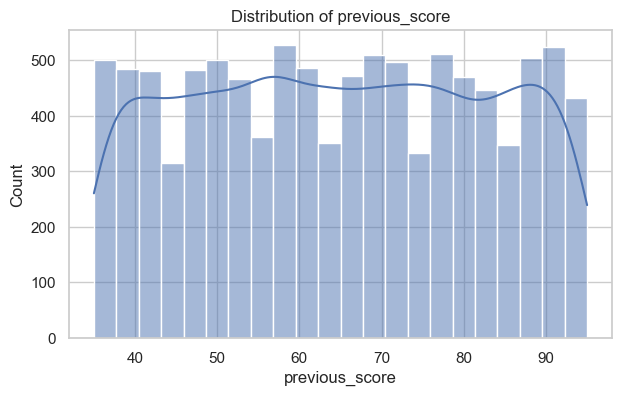

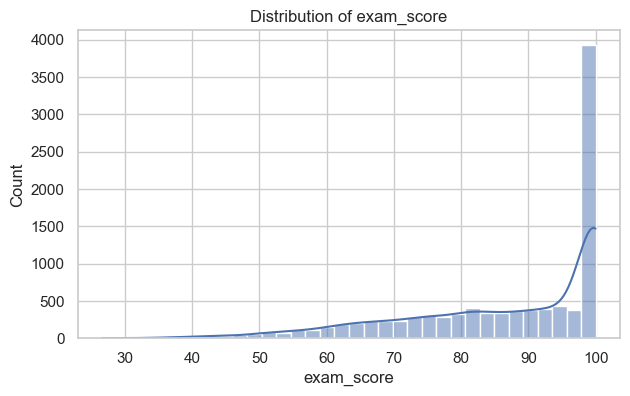

In [6]:
for column in numerical_columns:

    plt.figure(figsize=(7, 4))

    sns.histplot(
        df[column],
        kde=True
    )

    plt.title(f"Distribution of {column}")

    plt.show()

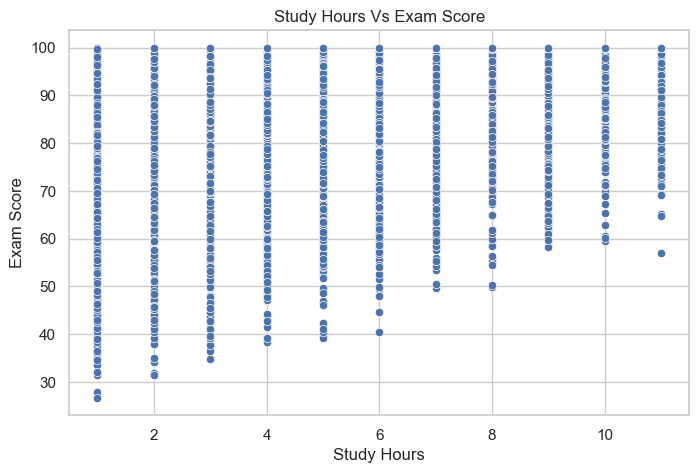

In [7]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,x="study_hours",y="exam_score")

plt.title("Study Hours Vs Exam Score")
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.show()

In [14]:
correlation = df.corr(
    numeric_only=True
)

print(correlation["exam_score"].sort_values(
    ascending=False
))

exam_score               1.000000
study_hours              0.562528
assignments_completed    0.387609
previous_score           0.318805
attendance               0.223367
sleep_hours              0.144675
internet_usage          -0.151896
Name: exam_score, dtype: float64


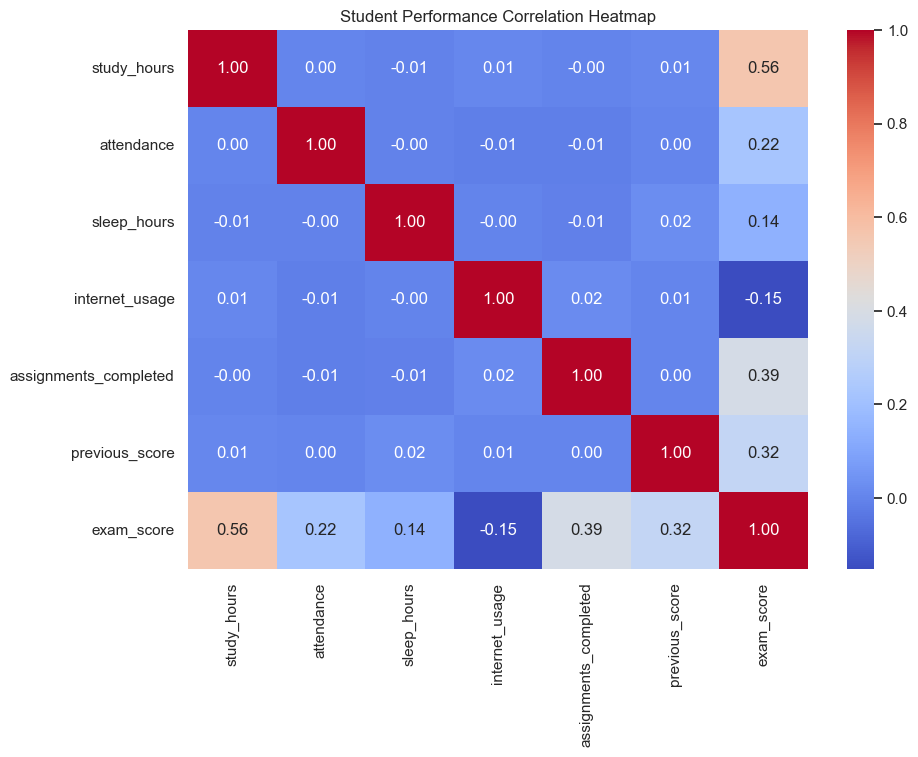

In [15]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation Heatmap")

plt.show()

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [29]:
X = df.drop(columns=["internet_usage","exam_score","placement_status"], axis=1)

y = df["exam_score"]

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (10000, 5)
Output shape: (10000,)


In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 5)
Testing data: (2000, 5)


In [31]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [32]:
y_pred = model.predict(X_test)

print("Actual Scores:")
print(y_test.head(10).values)

print("Predicted Scores:")
print(y_pred[:10])

Actual Scores:
[100.    84.07  95.37  83.96  78.58 100.    83.98  93.85 100.   100.  ]
Predicted Scores:
[104.39002976  86.40480658  88.75838965  76.93511892  93.47247133
 105.3989582   96.68967965  92.99137868  97.82115031  99.7591165 ]


In [33]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 7.1962576059531544
MSE: 83.02907055775789
RMSE: 9.112028893597621
R2 Score: 0.6385941137932083


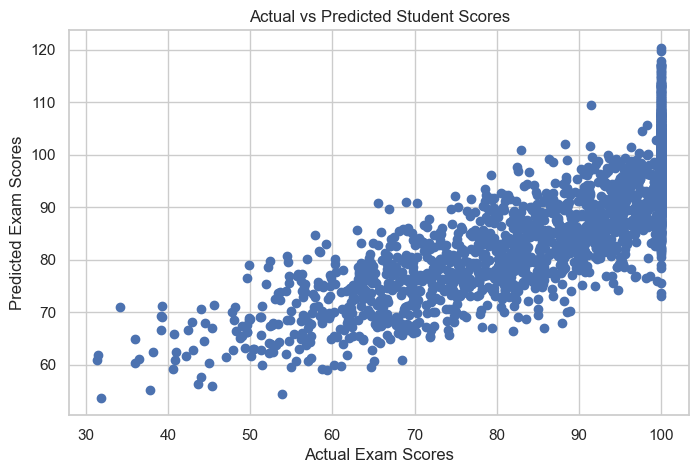

In [34]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Exam Scores")
plt.ylabel("Predicted Exam Scores")

plt.title("Actual vs Predicted Student Scores")

plt.show()

In [36]:
df.columns

Index(['study_hours', 'attendance', 'sleep_hours', 'internet_usage',
       'assignments_completed', 'previous_score', 'exam_score',
       'placement_status'],
      dtype='object')

In [46]:
new_student = pd.DataFrame({
    "study_hours": [8],
    "attendance": [50],
    "sleep_hours": [5],
    "assignments_completed": [5],
    "previous_score": [53]

})

prediction = model.predict(new_student)

print("Predicted Exam Score:", prediction[0])

Predicted Exam Score: 78.30468600701641


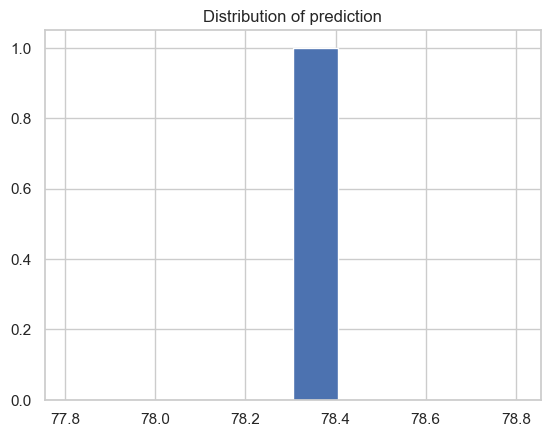

In [50]:
plt.hist(prediction)

plt.title(f"Distribution of prediction")
plt.show()